<a href="https://colab.research.google.com/github/matteogolfarelli/DataCentricAI/blob/main/Outlier%20Detection/kNN_outlier_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Distance-based outlier detection with kNN: masking and swamping
**Data Centric AI – Outlier detection**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/matteogolfarelli/DataCentricAI/blob/main/Outlier%20Detection/kNN_outlier_detection.ipynb)

This notebook shows the **distance-based approach** at work (slides *Distance-based Approaches*) and focuses on its two typical errors:

* **Masking**: labelling anomalous points as normal;
* **Swamping**: labelling normal points as anomalies.

The anomaly score of a point is the **average distance to its k nearest neighbors**. We will see how the choice of *k* moves the method from masking to swamping, and why no value of *k* can handle a dataset with variable density.

The same dataset is reused in the density-based, LOF and Isolation Forest notebooks, so that the results can be compared. Runs on CPU in a few seconds.

## 1. The dataset
A synthetic 2-D dataset built to contain the different situations discussed in the slides:

| Group | Points | Description |
|---|---|---|
| A | 300 | **dense** cluster (σ = 0.2) |
| B | 200 | **sparse** cluster (σ = 1.2) |
| C | 10 | **small but normal** cluster (e.g. a rare, legitimate customer profile) |
| global | 4 | isolated outliers, far from everything |
| group | 5 | outliers close to each other (e.g. the same fraud repeated 5 times) |
| local | 4 | outliers close to the dense cluster A: far from A, but not far in absolute terms |

The approach is **unsupervised**: labels are never used by the detector, only to evaluate it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.metrics import roc_auc_score
import pandas as pd

def make_dataset(seed=0):
    """2-D dataset shared by the kNN, density, LOF and iForest examples."""
    rng = np.random.default_rng(seed)
    A = rng.normal([0, 0], 0.2, (300, 2))          # dense cluster
    B = rng.normal([6, 0], 1.2, (200, 2))          # sparse cluster
    C = rng.normal([2.5, 5.0], 0.15, (10, 2))      # small, but NORMAL, cluster
    glob = np.array([[-4., -4.], [3., -5.], [11., 5.], [10., -5.]])   # global outliers
    grp  = rng.normal([-3.5, 3.0], 0.08, (5, 2))   # group of outliers (micro-cluster)
    ang  = np.array([0.3, 1.9, 3.4, 4.9])
    loc  = np.c_[1.3*np.cos(ang), 1.3*np.sin(ang)] # local outliers close to A
    X = np.vstack([A, B, C, glob, grp, loc])
    kind = np.array(['A']*300 + ['B']*200 + ['C']*10 + ['global']*4 + ['group']*5 + ['local']*4)
    y = np.isin(kind, ['global', 'group', 'local']).astype(int)   # 1 = outlier (used ONLY to evaluate)
    return X, y, kind

X, y, kind = make_dataset()
N_OUT = int(y.sum())                 # 13 outliers out of 523 points
TYPES = ['global', 'group', 'local', 'A', 'B', 'C']
print(X.shape, '-', N_OUT, 'outliers')
pd.Series(kind).value_counts().reindex(TYPES).to_frame('points').T

(523, 2) - 13 outliers


,global,group,local,A,B,C
points,4,5,4,300,200,10


In [2]:
NORM_C, OUT_C, FP_C = '#4C78A8', '#C0392B', '#E67E22'

def top_n(score, n=N_OUT):
    """Unsupervised labelling: the n points with the highest anomaly score are outliers."""
    flag = np.zeros(len(score), bool)
    flag[np.argsort(-score)[:n]] = True
    return flag

def evaluate(score, name='', n=N_OUT):
    """Ground truth is used only here, to assess the result."""
    f = top_n(score, n)
    row = {'ROC AUC': round(roc_auc_score(y, score), 3), 'P@n': round(y[f].mean(), 2)}
    row.update({f'{t} flagged': int(f[kind == t].sum()) for t in TYPES})
    return pd.DataFrame(row, index=[name])

def detect_plot(ax, score, title='', n=N_OUT):
    f = top_n(score, n)
    tp, fp, fn = f & (y == 1), f & (y == 0), ~f & (y == 1)
    ax.scatter(*X[(y == 0) & ~fp].T, s=12, c=NORM_C, alpha=.45, lw=0, label='normal')
    ax.scatter(*X[tp].T, s=55, marker='x', c=OUT_C, lw=1.8, label=f'detected outliers TP ({tp.sum()})')
    ax.scatter(*X[fn].T, s=90, facecolors='none', edgecolors='k', lw=1.4, label=f'missed outliers FN ({fn.sum()})')
    ax.scatter(*X[fp].T, s=60, c=FP_C, edgecolors='k', lw=.5, label=f'false alarms FP ({fp.sum()})')
    ax.set_title(title); ax.set_aspect('equal')
    ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')

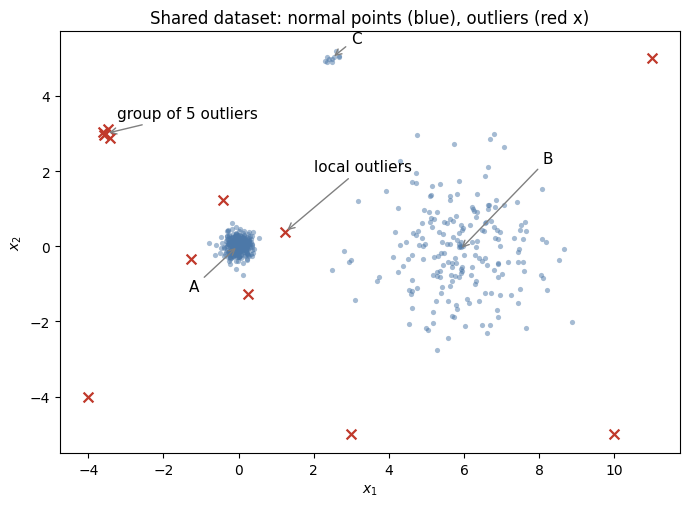

In [3]:
fig, ax = plt.subplots(figsize=(8, 6))
style = {'A': (NORM_C, 'o'), 'B': (NORM_C, 'o'), 'C': (NORM_C, 'o'),
         'global': (OUT_C, 'x'), 'group': (OUT_C, 'x'), 'local': (OUT_C, 'x')}
for t, (c, m) in style.items():
    ax.scatter(*X[kind == t].T, s=14 if m == 'o' else 50, c=c, marker=m, alpha=.5 if m == 'o' else 1, lw=1.6 if m == 'x' else 0)
for t, (dx, dy) in {'A': (-1.3, -1.2), 'B': (2.2, 2.3), 'C': (0.5, 0.4), 'group': (0.3, 0.4)}.items():
    cx, cy = X[kind == t].mean(axis=0)
    ax.annotate(t if t != 'group' else 'group of 5 outliers', (cx, cy), (cx + dx, cy + dy), fontsize=11,
                arrowprops=dict(arrowstyle='->', color='gray'))
ax.annotate('local outliers', (1.24, 0.38), (2.0, 2.0), fontsize=11, arrowprops=dict(arrowstyle='->', color='gray'))
ax.set_title('Shared dataset: normal points (blue), outliers (red x)'); ax.set_aspect('equal')
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); plt.show()

## 2. The kNN outlier score
$$score(x,k)=\frac{1}{k}\sum_{y\in N(x,k)} dist(x,y)$$
Since the approach is unsupervised we use the **top-n** definition of outlier (*"find all points having the top-n levels of anomaly"*), with *n* = 13 = number of true outliers. We measure:
* **P@n**: fraction of true outliers among the top-n points (here P@n = recall@n);
* **ROC AUC**: quality of the whole ranking, independent from the threshold.

Note: computing the neighbors of all the points costs O(N²) with a brute-force search.

In [4]:
def knn_score(X, k):
    # k+1 because the nearest neighbor of each point is the point itself
    dist, _ = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)
    return dist[:, 1:].mean(axis=1)

## 3. Small k (k = 1): masking
With k = 1 the score is the distance to the nearest neighbor. Each point of the *group* has a very close companion, so its score is tiny: the 5 outliers **mask each other**. Their places in the top-n are taken by normal points of the sparse cluster B (**swamping**).

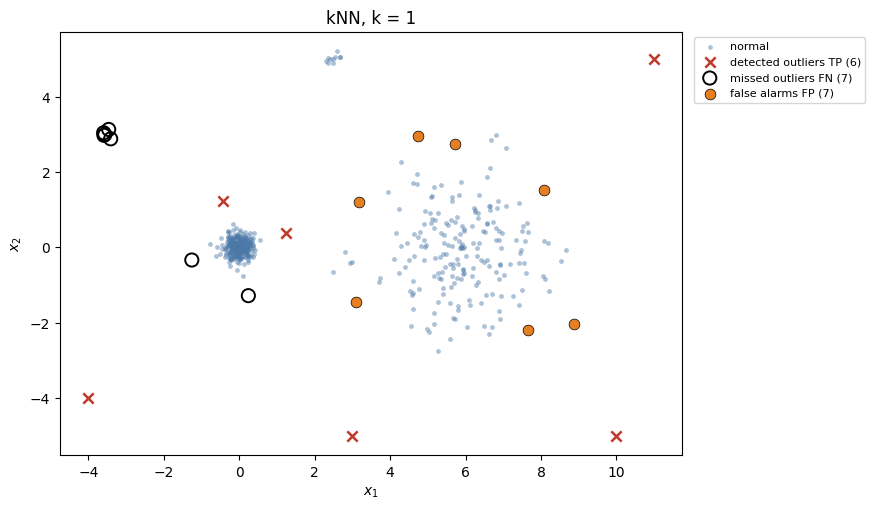

,ROC AUC,P@n,global flagged,group flagged,local flagged,A flagged,B flagged,C flagged
kNN k=1,0.853,0.46,4,0,2,0,7,0


In [5]:
s1 = knn_score(X, 1)
fig, ax = plt.subplots(figsize=(9, 5.5)); detect_plot(ax, s1, 'kNN, k = 1'); plt.show()
evaluate(s1, 'kNN k=1')

In [6]:
# Why? Compare the 1-NN distance of the group with that of the sparse cluster B
for t in ['group', 'B', 'global']:
    print(f'{t:7s} median 1-NN distance = {np.median(s1[kind == t]):.3f}')

group   median 1-NN distance = 0.058
B       median 1-NN distance = 0.135
global  median 1-NN distance = 3.865


## 4. k larger than the group (k = 10): masking is solved
When k exceeds the size of the group, the neighborhood of each member includes points of the rest of the dataset and the score grows. The **local outliers** are still missed: they are close to A in absolute terms, and many normal points of the sparse cluster B are farther from their neighbors.

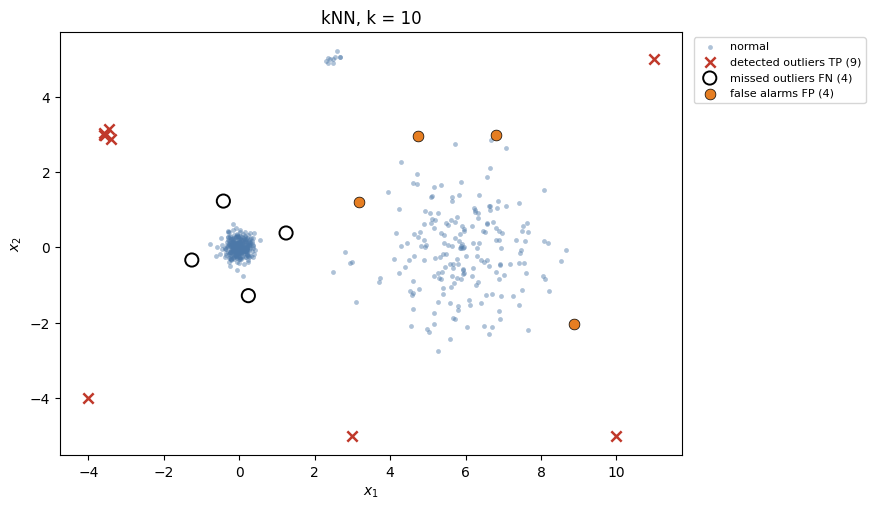

,ROC AUC,P@n,global flagged,group flagged,local flagged,A flagged,B flagged,C flagged
kNN k=10,0.989,0.69,4,5,0,0,4,0


In [7]:
s10 = knn_score(X, 10)
fig, ax = plt.subplots(figsize=(9, 5.5)); detect_plot(ax, s10, 'kNN, k = 10'); plt.show()
evaluate(s10, 'kNN k=10')

## 5. Too large k (k = 20): swamping of the small cluster
When k exceeds the size of the small **normal** cluster C, its points must look for neighbors outside C and become "far" from the rest of the data: they are swamped.

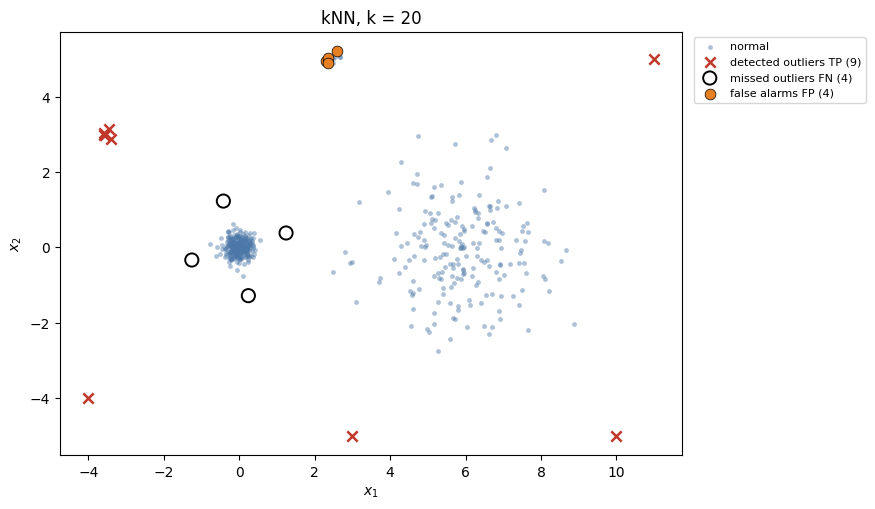

,ROC AUC,P@n,global flagged,group flagged,local flagged,A flagged,B flagged,C flagged
kNN k=20,0.979,0.69,4,5,0,0,0,4


In [12]:
s20 = knn_score(X, 20)
fig, ax = plt.subplots(figsize=(9, 5.5)); detect_plot(ax, s20, 'kNN, k = 20'); plt.show()
evaluate(s20, 'kNN k=20')

## 6. Sensitivity to k
We repeat the experiment for k = 1 … 40 and count, for each type of point, how many are in the top-n.

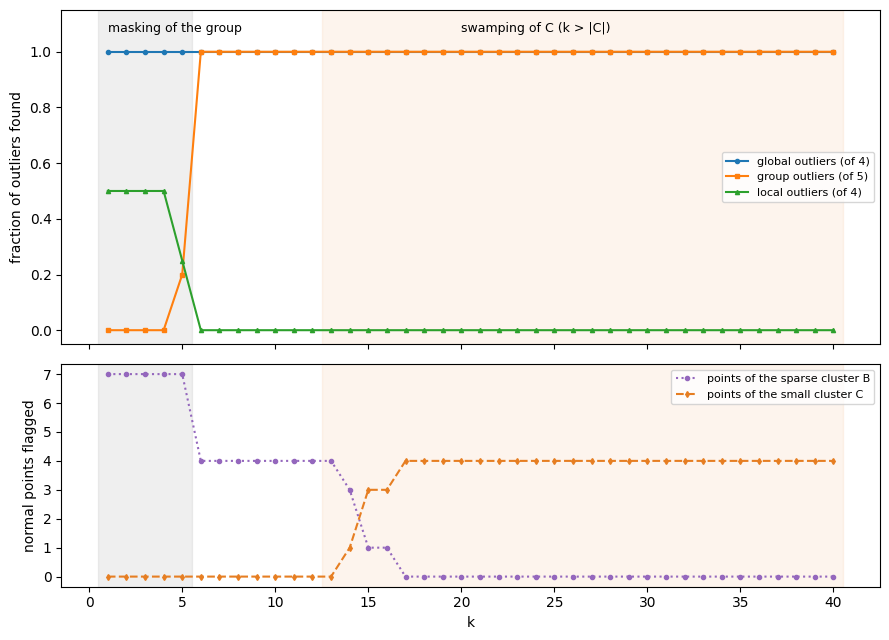

,ROC AUC,P@n,global flagged,group flagged,local flagged,B flagged,C flagged
1,0.853,0.46,4,0,2,7,0
5,0.990,0.46,4,1,1,7,0
8,0.991,0.69,4,5,0,4,0
10,0.989,0.69,4,5,0,4,0
15,0.982,0.69,4,5,0,1,3
20,0.979,0.69,4,5,0,0,4
30,0.971,0.69,4,5,0,0,4


In [9]:
ks = list(range(1, 41))
res = pd.concat([evaluate(knn_score(X, k), k) for k in ks])
res['normal flagged (FP)'] = res[['A flagged', 'B flagged', 'C flagged']].sum(axis=1)

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True, height_ratios=[3, 2])
ax.plot(ks, res['global flagged'] / 4, 'o-', ms=3, label='global outliers (of 4)')
ax.plot(ks, res['group flagged'] / 5, 's-', ms=3, label='group outliers (of 5)')
ax.plot(ks, res['local flagged'] / 4, '^-', ms=3, label='local outliers (of 4)')
ax.set_ylabel('fraction of outliers found'); ax.set_ylim(-0.05, 1.15); ax.legend(fontsize=8, loc='center right')
ax2.plot(ks, res['B flagged'], 'o:', ms=3, c='tab:purple', label='points of the sparse cluster B')
ax2.plot(ks, res['C flagged'], 'd--', ms=3, c=FP_C, label='points of the small cluster C')
ax2.set_ylabel('normal points flagged'); ax2.set_xlabel('k'); ax2.legend(fontsize=8)
for a in (ax, ax2):
    a.axvspan(0.5, 5.5, color='gray', alpha=.12); a.axvspan(12.5, 40.5, color=FP_C, alpha=.08)
ax.text(1, 1.07, 'masking of the group', fontsize=9); ax.text(20, 1.07, 'swamping of C (k > |C|)', fontsize=9)
plt.tight_layout(); plt.show()
res.loc[[1, 5, 8, 10, 15, 20, 30], ['ROC AUC', 'P@n', 'global flagged', 'group flagged', 'local flagged', 'B flagged', 'C flagged']]

Observations
* **No value of k finds the local outliers** (apart from very small k, where one or two are found "by chance" while the group is masked): P@n never exceeds 0.69.
* The ROC AUC stays high (≈ 0.99 for k ≈ 8–10): the local outliers are ranked *just after* some points of B. The ranking is good on average, but the **top of the list** – the part we look at – is wrong.

## 7. Why the local outliers are missed: a single scale for the whole dataset

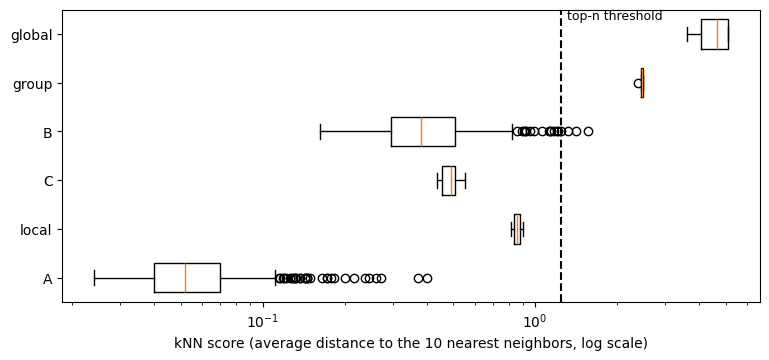

local outliers: score [0.82 0.85 0.88 0.9 ]
points of B with a higher score: 19


In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
groups = ['A', 'local', 'C', 'B', 'group', 'global']
ax.boxplot([s10[kind == t] for t in groups], vert=False, tick_labels=groups, widths=.6)
thr = np.sort(s10)[-N_OUT]
ax.axvline(thr, ls='--', c='k'); ax.text(thr * 1.05, 6.3, 'top-n threshold', fontsize=9)
ax.set_xscale('log'); ax.set_xlabel('kNN score (average distance to the 10 nearest neighbors, log scale)')
plt.show()
print('local outliers: score', np.round(np.sort(s10[kind == "local"]), 2))
print('points of B with a higher score:', int((s10[kind == "B"] > s10[kind == "local"].min()).sum()))

The local outliers are **about 15 times farther** from their neighbors than the points of A, but they are compared with **one global threshold**, which must also accept the points of the sparse cluster B. This is the limit discussed in the slides (*"C is properly identified, but what about D?"*) and the motivation for density-based approaches and LOF.

## Takeaways
**Pros**
* Simple and intuitive; no assumption on the data distribution.
* One parameter (k); works well for **global** outliers.
* With k larger than the size of the anomalous groups it also finds **grouped** outliers.

**Cons**
* **Sensitive to k**: small k → masking of groups of outliers; large k → swamping of small normal clusters.
* **Cannot handle datasets with variable density**: one global scale for the whole dataset.
* O(N²) complexity (brute force); distances lose meaning in high dimensions.
* A good ROC AUC does not guarantee good top-n results.

**Try yourself**: move the local outliers farther from A (e.g. radius 2.5 instead of 1.3), or make the group larger than 10 points, and look again at the sweep on k.